In [1]:
# ============================================================
# FULL SCRIPT (WITH RELIABILITY PLOTS FOR ALL METHODS)
# ============================================================

import os, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.manifold import TSNE

print("Torch:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# ===== Data =====
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

train_tfms = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
test_tfms = T.Compose([
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

root = "./data"
full_train = torchvision.datasets.CIFAR10(root=root, train=True, download=True, transform=train_tfms)
test_ds    = torchvision.datasets.CIFAR10(root=root, train=False, download=True, transform=test_tfms)

val_size = 5000
train_size = len(full_train) - val_size
train_ds, val_ds = random_split(
    full_train, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Val WITHOUT augmentation
full_train_noaug = torchvision.datasets.CIFAR10(root=root, train=True, download=False, transform=test_tfms)
val_ds   = Subset(full_train_noaug, val_ds.indices)
train_ds = Subset(full_train,       train_ds.indices)

batch_size = 128
num_workers = 2
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)

print("Train:", len(train_ds), "Val:", len(val_ds), "Test:", len(test_ds))

# ===== Model =====
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 8x8
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*4*4, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# ===== Logits / Accuracy / ECE / Reliability Bins =====
@torch.no_grad()
def collect_logits_labels(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        logits = model(x)
        all_logits.append(logits.detach().cpu())
        all_labels.append(y.detach().cpu())
    return torch.cat(all_logits, dim=0), torch.cat(all_labels, dim=0)

@torch.no_grad()
def accuracy_from_logits(logits, labels):
    return float((logits.argmax(dim=1) == labels).float().mean().item())

def compute_ece_and_bins(logits, labels, n_bins=15):
    probs = torch.softmax(logits, dim=1)
    conf, preds = probs.max(dim=1)
    correct = preds.eq(labels).float()

    bins = torch.linspace(0.0, 1.0, n_bins + 1)
    ece = torch.zeros(1)

    bin_accs, bin_confs, bin_counts = [], [], []
    N = len(labels)

    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        in_bin = (conf > lo) & (conf <= hi)
        count = in_bin.float().sum().item()
        if count > 0:
            acc_in_bin  = correct[in_bin].mean().item()
            conf_in_bin = conf[in_bin].mean().item()
            ece += torch.tensor([(count / N) * abs(acc_in_bin - conf_in_bin)])
            bin_accs.append(acc_in_bin)
            bin_confs.append(conf_in_bin)
            bin_counts.append(int(count))
        else:
            bin_accs.append(0.0)
            bin_confs.append(0.0)
            bin_counts.append(0)

    return float(ece.item()), np.array(bin_accs), np.array(bin_confs), np.array(bin_counts), bins.numpy()

def plot_reliability_diagram(bin_accs, bins, title="Reliability Diagram"):
    centers = (bins[:-1] + bins[1:]) / 2.0
    widths  = (bins[1:] - bins[:-1])

    plt.figure(figsize=(6,6))
    plt.plot([0,1], [0,1])
    plt.bar(centers, bin_accs, width=widths, align="center", edgecolor="black", alpha=0.8)
    plt.xlabel("Confidence")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.ylim(0, 1); plt.xlim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.show()

@torch.no_grad()
def evaluate_pack(model, loader, n_bins=15):
    logits, labels = collect_logits_labels(model, loader)
    acc = accuracy_from_logits(logits, labels)
    ece, bin_accs, bin_confs, bin_counts, bins = compute_ece_and_bins(logits, labels, n_bins=n_bins)
    return acc, ece, (logits, labels), (bin_accs, bin_confs, bin_counts, bins)

# ===== Temperature scaling =====
def temperature_scale(logits, T):
    return logits / T

def find_best_temperature(val_logits, val_labels, n_bins=15, bounds=(0.01, 5.0)):
    def obj(T):
        scaled = temperature_scale(val_logits, T)
        ece, *_ = compute_ece_and_bins(scaled, val_labels, n_bins=n_bins)
        return ece
    res = minimize_scalar(obj, bounds=bounds, method="bounded")
    return float(res.x)

# ===== Margin calibration loss =====
def calibration_loss_from_logits(logits, labels, margin=1.0):
    correct_logits = logits.gather(1, labels.unsqueeze(1)).squeeze(1)
    logits_clone = logits.clone()
    logits_clone[torch.arange(logits.size(0), device=logits.device), labels] = float("-inf")
    max_wrong = logits_clone.max(dim=1)[0]
    hinge = max_wrong - correct_logits - margin
    return torch.clamp(hinge, min=0.0).mean()

# ===== Training =====
def train_one_epoch(model, loader, optimizer, lambda_calib=0.0, margin=1.0):
    model.train()
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        ce = F.cross_entropy(logits, y)
        if lambda_calib > 0.0:
            cal = calibration_loss_from_logits(logits, y, margin=margin)
            loss = ce + lambda_calib * cal
        else:
            loss = ce
        loss.backward()
        optimizer.step()



Torch: 2.6.0+cu124
Device: cuda


100%|██████████| 170M/170M [00:04<00:00, 35.0MB/s] 


Train: 45000 Val: 5000 Test: 10000


In [2]:
def train_select_best(
    lambda_calib,
    margin,
    epochs=200,
    lr=1e-3,
    weight_decay=0.0,
    n_bins=15,
    save_path="best.pt",
    select_by="val_acc",  # "val_acc" or "val_ece"
    verbose=True
):
    model = SimpleCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val_acc = -1.0
    best_val_ece = float("inf")
    best_epoch = None

    for ep in range(1, epochs + 1):
        train_one_epoch(model, train_loader, optimizer, lambda_calib=lambda_calib, margin=margin)
        val_acc, val_ece, _, _ = evaluate_pack(model, val_loader, n_bins=n_bins)

        if verbose:
            print(f"[lambda={lambda_calib}, m={margin}] ep {ep:03d}/{epochs} | "
                  f"val_acc={val_acc*100:.2f}% | val_ece={val_ece:.4f}")

        improved = False
        if select_by == "val_acc":
            if val_acc > best_val_acc:
                improved = True
        else:  # val_ece
            if val_ece < best_val_ece:
                improved = True

        if improved:
            best_val_acc = val_acc
            best_val_ece = val_ece
            best_epoch = ep
            torch.save(
                {"model_state": model.state_dict(),
                 "lambda_calib": lambda_calib,
                 "margin": margin,
                 "epoch": ep},
                save_path
            )

    ckpt = torch.load(save_path, map_location=device)
    model.load_state_dict(ckpt["model_state"])

    # Final VAL + TEST packs
    val_acc, val_ece, val_pack, val_rel = evaluate_pack(model, val_loader, n_bins=n_bins)
    test_acc, test_ece, test_pack, test_rel = evaluate_pack(model, test_loader, n_bins=n_bins)

    return model, best_epoch, (val_acc, val_ece, val_pack, val_rel), (test_acc, test_ece, test_pack, test_rel)




================ BASELINE (CE) ================
[lambda=0.0, m=1.0] ep 001/200 | val_acc=47.92% | val_ece=0.0752
[lambda=0.0, m=1.0] ep 002/200 | val_acc=58.16% | val_ece=0.0333
[lambda=0.0, m=1.0] ep 003/200 | val_acc=64.96% | val_ece=0.0172
[lambda=0.0, m=1.0] ep 004/200 | val_acc=65.44% | val_ece=0.0139
[lambda=0.0, m=1.0] ep 005/200 | val_acc=71.08% | val_ece=0.0118
[lambda=0.0, m=1.0] ep 006/200 | val_acc=73.30% | val_ece=0.0161
[lambda=0.0, m=1.0] ep 007/200 | val_acc=75.90% | val_ece=0.0174
[lambda=0.0, m=1.0] ep 008/200 | val_acc=76.32% | val_ece=0.0295
[lambda=0.0, m=1.0] ep 009/200 | val_acc=77.78% | val_ece=0.0203
[lambda=0.0, m=1.0] ep 010/200 | val_acc=77.72% | val_ece=0.0155
[lambda=0.0, m=1.0] ep 011/200 | val_acc=79.26% | val_ece=0.0113
[lambda=0.0, m=1.0] ep 012/200 | val_acc=79.26% | val_ece=0.0168
[lambda=0.0, m=1.0] ep 013/200 | val_acc=79.94% | val_ece=0.0150
[lambda=0.0, m=1.0] ep 014/200 | val_acc=79.76% | val_ece=0.0239
[lambda=0.0, m=1.0] ep 015/200 | val_acc=

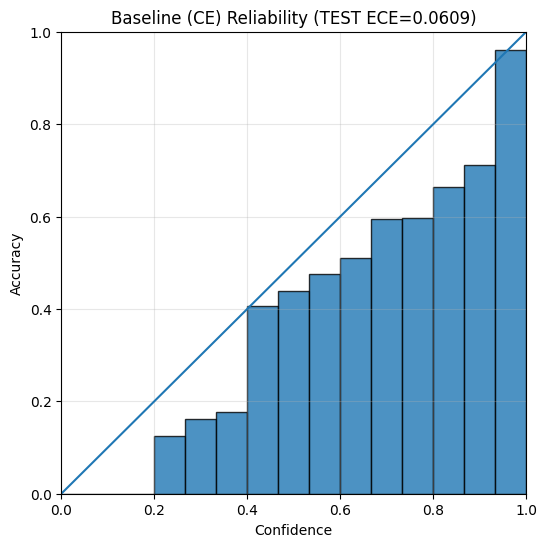


================ TEMPERATURE SCALING (baseline) ================
Best T (VAL-fit): 1.5990
TempScaled TEST acc=85.84% | TEST ece=0.0175


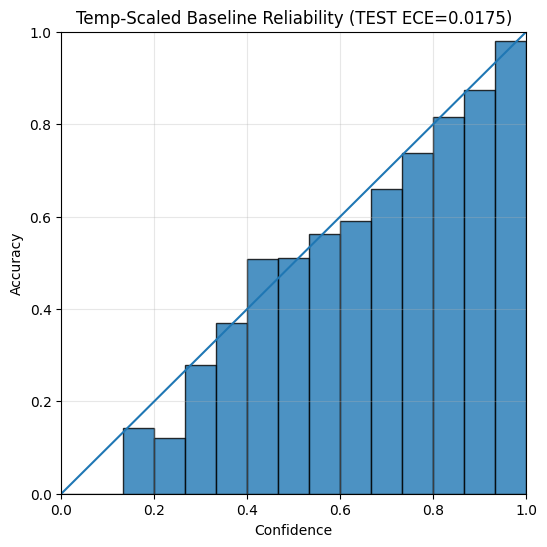

In [3]:
# ============================================================
# MAIN EXPERIMENT
# ============================================================
EPOCHS = 200
LR = 1e-3
WD = 0.0
N_BINS = 15

# ---- 1) Baseline (CE) ----
print("\n================ BASELINE (CE) ================")
baseline_model, base_best_ep, base_val, base_test = train_select_best(
    lambda_calib=0.0,
    margin=1.0,
    epochs=EPOCHS,
    lr=LR,
    weight_decay=WD,
    n_bins=N_BINS,
    save_path="baseline_best.pt",
    select_by="val_acc",
    verbose=True
)

base_val_acc, base_val_ece, (base_val_logits, base_val_labels), base_val_rel = base_val
base_test_acc, base_test_ece, (base_test_logits, base_test_labels), base_test_rel = base_test
base_bin_accs, base_bin_confs, base_bin_counts, base_bins = base_test_rel

print("\nBaseline best epoch:", base_best_ep)
print(f"Baseline TEST acc={base_test_acc*100:.2f}% | TEST ece={base_test_ece:.4f}")

# Reliability plot: Baseline
plot_reliability_diagram(base_bin_accs, base_bins, title=f"Baseline (CE) Reliability (TEST ECE={base_test_ece:.4f})")

# ---- 2) Temperature scaling on baseline ----
print("\n================ TEMPERATURE SCALING (baseline) ================")
best_T = find_best_temperature(base_val_logits, base_val_labels, n_bins=N_BINS, bounds=(0.01, 5.0))
scaled_test_logits = temperature_scale(base_test_logits, best_T)

ts_test_acc = accuracy_from_logits(scaled_test_logits, base_test_labels)
ts_test_ece, ts_bin_accs, ts_bin_confs, ts_bin_counts, ts_bins = compute_ece_and_bins(
    scaled_test_logits, base_test_labels, n_bins=N_BINS
)

print(f"Best T (VAL-fit): {best_T:.4f}")
print(f"TempScaled TEST acc={ts_test_acc*100:.2f}% | TEST ece={ts_test_ece:.4f}")

# Reliability plot: Temperature-scaled baseline
plot_reliability_diagram(ts_bin_accs, ts_bins, title=f"Temp-Scaled Baseline Reliability (TEST ECE={ts_test_ece:.4f})")


================ MARGIN SWEEP (select by VAL ECE) ================

--- Training margin=0.1 ---
[lambda=0.1, m=0.1] ep 001/200 | val_acc=50.16% | val_ece=0.0254
[lambda=0.1, m=0.1] ep 002/200 | val_acc=62.30% | val_ece=0.0623
[lambda=0.1, m=0.1] ep 003/200 | val_acc=66.18% | val_ece=0.0250
[lambda=0.1, m=0.1] ep 004/200 | val_acc=70.56% | val_ece=0.0322
[lambda=0.1, m=0.1] ep 005/200 | val_acc=71.96% | val_ece=0.0325
[lambda=0.1, m=0.1] ep 006/200 | val_acc=74.00% | val_ece=0.0283
[lambda=0.1, m=0.1] ep 007/200 | val_acc=75.46% | val_ece=0.0167
[lambda=0.1, m=0.1] ep 008/200 | val_acc=76.72% | val_ece=0.0404
[lambda=0.1, m=0.1] ep 009/200 | val_acc=78.74% | val_ece=0.0197
[lambda=0.1, m=0.1] ep 010/200 | val_acc=78.32% | val_ece=0.0127
[lambda=0.1, m=0.1] ep 011/200 | val_acc=80.88% | val_ece=0.0400
[lambda=0.1, m=0.1] ep 012/200 | val_acc=80.28% | val_ece=0.0181
[lambda=0.1, m=0.1] ep 013/200 | val_acc=78.98% | val_ece=0.0165
[lambda=0.1, m=0.1] ep 014/200 | val_acc=81.38% | val_ece=

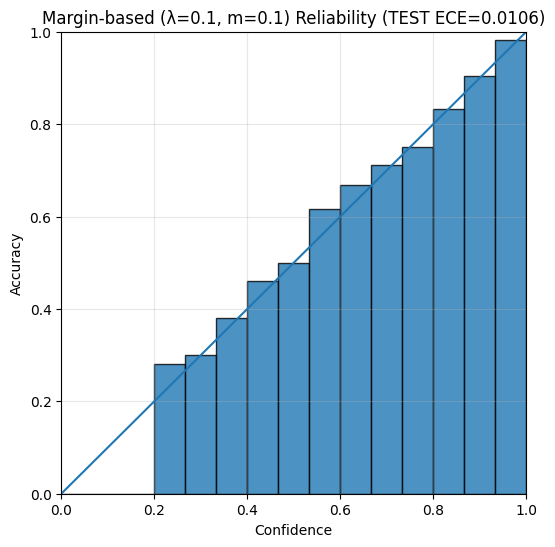

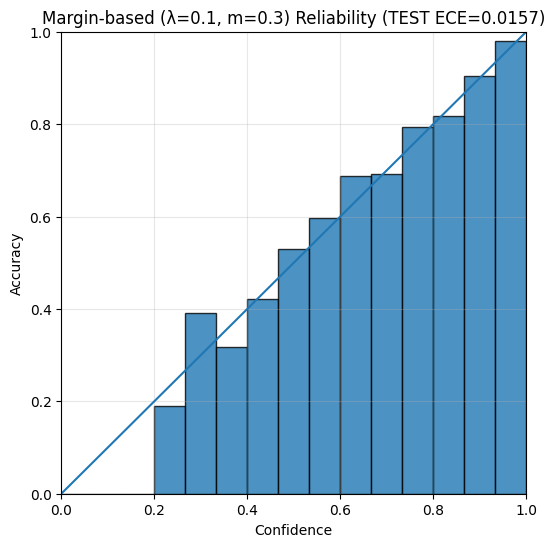

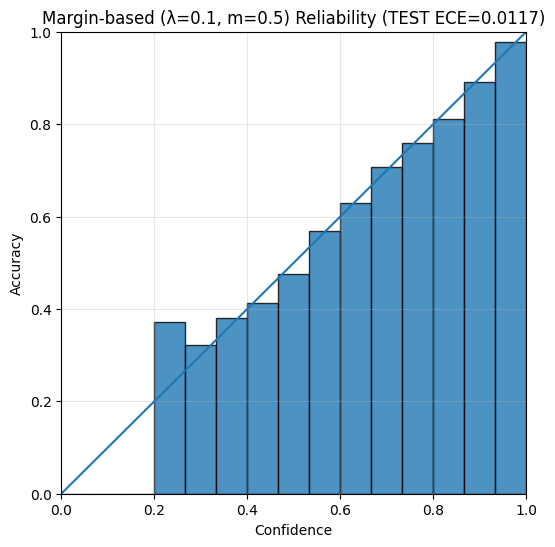

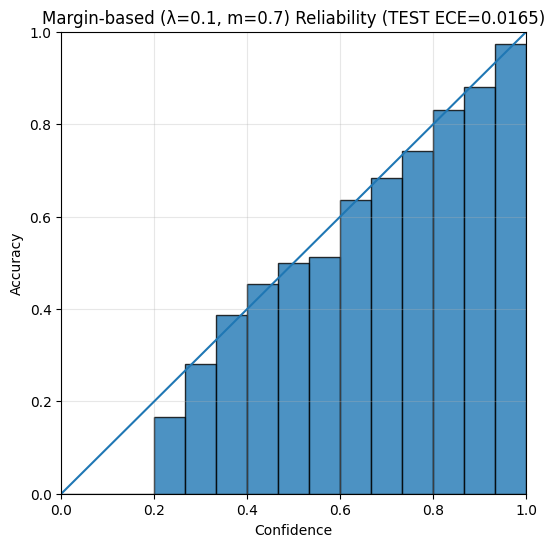

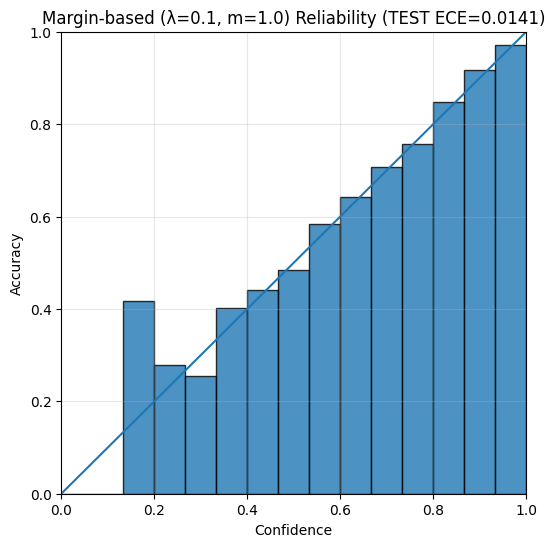

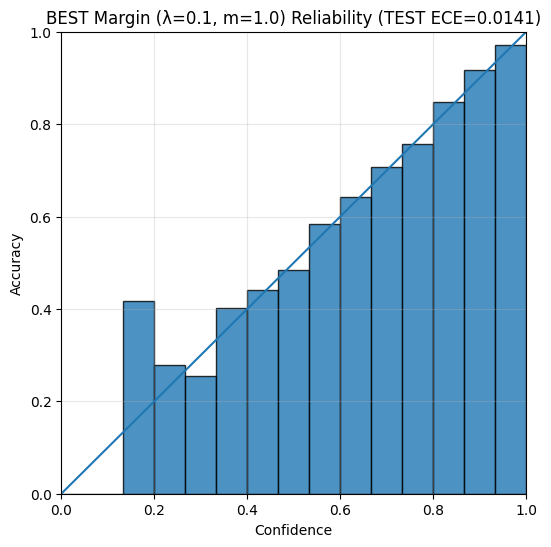

In [4]:
# ---- 3) Margin sweep ----
print("\n================ MARGIN SWEEP (select by VAL ECE) ================")
LAMBDA_CAL = 0.1
margins = [0.1, 0.3, 0.5, 0.7, 1.0]

results = {}
best_margin = None
best_val_ece_global = float("inf")

for m in margins:
    print(f"\n--- Training margin={m} ---")
    m_model, m_best_ep, m_val, m_test = train_select_best(
        lambda_calib=LAMBDA_CAL,
        margin=m,
        epochs=EPOCHS,
        lr=LR,
        weight_decay=WD,
        n_bins=N_BINS,
        save_path=f"margin_{m}_best.pt",
        select_by="val_ece",
        verbose=True
    )

    m_val_acc, m_val_ece, m_val_pack, m_val_rel = m_val
    m_test_acc, m_test_ece, m_test_pack, m_test_rel = m_test

    results[m] = {
        "model": m_model,
        "best_epoch": m_best_ep,
        "val_acc": m_val_acc,
        "val_ece": m_val_ece,
        "test_acc": m_test_acc,
        "test_ece": m_test_ece,
        "test_rel": m_test_rel
    }

    # pick best margin by LOWEST VAL ECE
    if m_val_ece < best_val_ece_global:
        best_val_ece_global = m_val_ece
        best_margin = m

# ---- Summary table ----
print("\n================ SUMMARY TABLE ================")
print("| method | margin | test_acc(%) | test_ece |")
print("|--------|--------|------------:|---------:|")
print(f"| Baseline (CE)     |   -   | {base_test_acc*100:>11.2f} | {base_test_ece:>8.4f} |")
print(f"| Temp-Scaled Base  |   -   | {ts_test_acc*100:>11.2f} | {ts_test_ece:>8.4f} |")
for m in margins:
    print(f"| Margin (λ={LAMBDA_CAL}) | {m:>4} | {results[m]['test_acc']*100:>11.2f} | {results[m]['test_ece']:>8.4f} |")

print("\n✅ BEST MARGIN (lowest VAL ECE):", best_margin)
print("✅ BEST VAL ECE:", best_val_ece_global)
print("   Best margin TEST acc/ece:",
      f"{results[best_margin]['test_acc']*100:.2f}% / {results[best_margin]['test_ece']:.4f}")

# ---- Reliability plots: each margin on TEST ----
for m in margins:
    bin_accs, bin_confs, bin_counts, bins = results[m]["test_rel"]
    plot_reliability_diagram(
        bin_accs, bins,
        title=f"Margin-based (λ={LAMBDA_CAL}, m={m}) Reliability (TEST ECE={results[m]['test_ece']:.4f})"
    )

# ---- Reliability plot: Best margin (again highlighted) ----
best_bin_accs, best_bin_confs, best_bin_counts, best_bins = results[best_margin]["test_rel"]
plot_reliability_diagram(
    best_bin_accs, best_bins,
    title=f"BEST Margin (λ={LAMBDA_CAL}, m={best_margin}) Reliability (TEST ECE={results[best_margin]['test_ece']:.4f})"
)



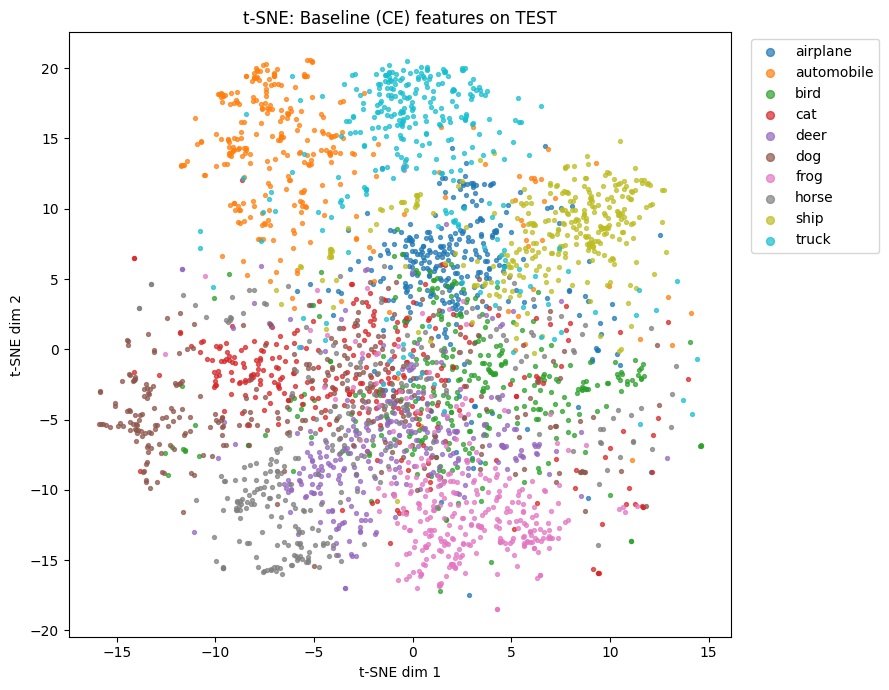

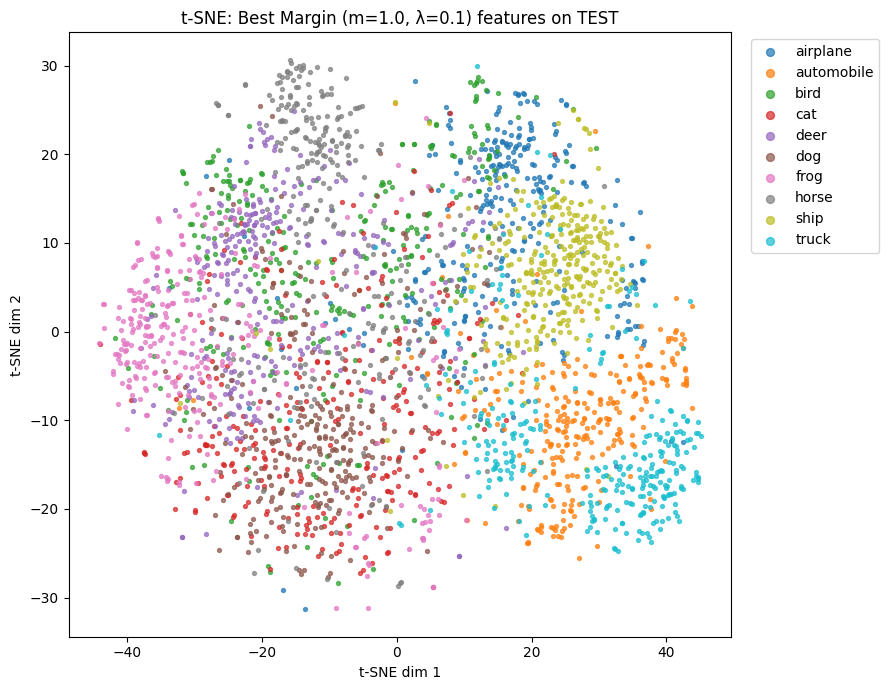

In [5]:
# ============================================================
# OPTIONAL: t-SNE plots (baseline vs best margin)
# ============================================================
@torch.no_grad()
def extract_features_and_labels(model, loader, max_samples=3000):
    model.eval()
    feats, labels = [], []
    seen = 0
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        f = model.features(x).flatten(1)  # (B,2048)
        feats.append(f.cpu())
        labels.append(y.cpu())
        seen += x.size(0)
        if seen >= max_samples:
            break
    feats = torch.cat(feats, dim=0)[:max_samples].numpy()
    labels = torch.cat(labels, dim=0)[:max_samples].numpy()
    return feats, labels

def plot_tsne(model, loader, title, max_samples=3000, perplexity=30, n_iter=1000, seed=42):
    X, y = extract_features_and_labels(model, loader, max_samples=max_samples)
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        n_iter=n_iter,
        init="pca",
        learning_rate="auto",
        random_state=seed
    )
    Z = tsne.fit_transform(X)

    classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
    plt.figure(figsize=(9, 7))
    for c in range(10):
        idx = (y == c)
        plt.scatter(Z[idx, 0], Z[idx, 1], s=8, alpha=0.7, label=classes[c])
    plt.title(title)
    plt.xlabel("t-SNE dim 1")
    plt.ylabel("t-SNE dim 2")
    plt.legend(markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

# Uncomment if you want t-SNE plots
plot_tsne(baseline_model, test_loader, title="t-SNE: Baseline (CE) features on TEST", max_samples=3000)
plot_tsne(results[best_margin]["model"], test_loader, title=f"t-SNE: Best Margin (m={best_margin}, λ={LAMBDA_CAL}) features on TEST", max_samples=3000)
